In [1]:
import sys

import matplotlib
import numpy
import pandas
import scipy
import sklearn

print(
    sys.version.split()[0],
    numpy.__version__,
    pandas.__version__,
    scipy.__version__,
    sklearn.__version__,
    matplotlib.__version__,
)

3.12.14 2.3.4 2.3.3 1.16.3 1.7.2 3.10.7


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

SEED = 3246

df = pd.read_csv("data/drybean.csv")
class_label = df.pop("Class").to_numpy()  # Reserved for the evaluation in Part 6.
X = df.to_numpy(dtype=float)
features = list(df.columns)
n = len(X)
print(X.shape, "missing values:", int(np.isnan(X).sum()))

(13543, 16) missing values: 0


In [3]:
Xs = StandardScaler().fit_transform(X)

**Seed.** `SEED = 3246`, the last four digits of my student ID.

## Part 1 - Audit of the data

In [4]:
feature_variances = df.var(ddof=0)
variance_shares = feature_variances / feature_variances.sum()

feature_audit = pd.DataFrame({
    "Mean": df.mean(),
    "Std (ddof=0)": df.std(ddof=0),
    "Min": df.min(),
    "Max": df.max(),
    "Share of total variance": variance_shares,
})

print(feature_audit.to_string(
    float_format=lambda value: f"{value:.4g}",
    formatters={"Share of total variance": lambda share: f"{100 * share:.4g}%"},
))

top_variance_features = variance_shares.nlargest(2)
print(f"Combined variance share of the two largest contributors: {top_variance_features.sum():.4%}")

                     Mean  Std (ddof=0)       Min       Max Share of total variance
Area            5.305e+04     2.939e+04 2.042e+04 2.546e+05                  49.24%
Perimeter             855         214.7     524.7      1985               0.002628%
MajorAxisLength     319.9         85.81     183.6     738.9              0.0004196%
MinorAxisLength     202.4         45.05     122.5     460.2              0.0001157%
AspectRatio         1.581        0.2452     1.025      2.43              3.428e-09%
Eccentricity       0.7503       0.09185     0.219    0.9114              4.809e-10%
ConvexArea      5.377e+04     2.984e+04 2.068e+04 2.633e+05                  50.76%
EquivDiameter         253         59.31     161.2     569.4              0.0002005%
Extent             0.7498       0.04894    0.5553    0.8662              1.365e-10%
Solidity           0.9872       0.00465    0.9192    0.9947              1.232e-12%
Roundness          0.8737       0.05939    0.4896    0.9907               2.

ConvexArea (50.7610%) and Area (49.2357%) together account for 99.9966% of the total variance on the original scales. Their large spread means differences in these two measurements can dominate Euclidean distances between grains before scaling.

In [5]:
pearson = df.corr(method="pearson").to_numpy()
first, second = np.triu_indices(len(features), k=1)
pair_correlations = pearson[first, second]
strong = np.abs(pair_correlations) > 0.95

strong_pairs = pd.DataFrame({
    "Feature 1": df.columns[first[strong]],
    "Feature 2": df.columns[second[strong]],
    "Pearson r": pair_correlations[strong],
})

print(f"Pairs with |Pearson r| > 0.95: {len(strong_pairs)}")
print(strong_pairs.to_string(index=False, float_format=lambda value: f"{value:.5f}"))

Pairs with |Pearson r| > 0.95: 15
      Feature 1       Feature 2  Pearson r
           Area       Perimeter    0.96691
           Area MinorAxisLength    0.95204
           Area      ConvexArea    0.99994
           Area   EquivDiameter    0.98500
      Perimeter MajorAxisLength    0.97756
      Perimeter      ConvexArea    0.96787
      Perimeter   EquivDiameter    0.99145
MajorAxisLength   EquivDiameter    0.96227
MinorAxisLength      ConvexArea    0.95178
    AspectRatio     Compactness   -0.98764
    AspectRatio    ShapeFactor3   -0.97853
   Eccentricity     Compactness   -0.97031
   Eccentricity    ShapeFactor3   -0.98106
     ConvexArea   EquivDiameter    0.98526
    Compactness    ShapeFactor3    0.99868


There are 15 pairs with an absolute Pearson correlation above 0.95. For example, Area and ConvexArea have a Pearson correlation of +0.99994. Area measures the grain silhouette and ConvexArea measures its convex hull, which fills in indentations. Larger grains generally have larger areas under both measurements.

## Part 2 - K-Means by hand and the effect of scaling

In [6]:
def lloyd_kmeans(X, init_centers, max_iter=300):
    """Return (labels, centers, inertia, n_iter)."""
    if max_iter < 1:
        raise ValueError("max_iter must be at least 1.")

    X = np.asarray(X, dtype=float)
    centers = np.array(init_centers, dtype=float, copy=True)
    labels = None

    for n_iter in range(1, max_iter + 1):
        previous_labels = labels
        differences = X[:, None, :] - centers[None, :, :]
        squared_distances = np.sum(differences ** 2, axis=2)
        labels = np.argmin(squared_distances, axis=1)

        for cluster in range(len(centers)):
            members = X[labels == cluster]
            if len(members):
                centers[cluster] = members.mean(axis=0)

        if previous_labels is not None and np.array_equal(labels, previous_labels):
            break

    residuals = X - centers[labels]
    inertia = float(np.sum(residuals ** 2))
    return labels, centers, inertia, n_iter

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

kmeans_clusters = 7
init = Xs[np.random.default_rng(SEED).choice(n, kmeans_clusters, replace=False)]
lloyd_labels, lloyd_centers, lloyd_inertia, lloyd_iterations = lloyd_kmeans(Xs, init)

reference_kmeans = KMeans(
    n_clusters=kmeans_clusters,
    init=init,
    n_init=1,
    algorithm="lloyd",
    tol=0.0,
    max_iter=300,
).fit(Xs)

labels_match = np.array_equal(lloyd_labels, reference_kmeans.labels_)
centers_match = np.allclose(
    lloyd_centers, reference_kmeans.cluster_centers_, rtol=1e-6, atol=0.0
)
inertia_match = np.isclose(lloyd_inertia, reference_kmeans.inertia_, rtol=1e-6, atol=0.0)

print(f"Identical labels: {labels_match}")
print(f"Centers match at rtol=1e-6: {centers_match}")
print(f"Inertia matches at rtol=1e-6: {inertia_match}")
print(f"Inertia (manual / scikit-learn): {lloyd_inertia:.6f} / {reference_kmeans.inertia_:.6f}")
print(f"Assignment steps (manual / scikit-learn): {lloyd_iterations} / {reference_kmeans.n_iter_}")

Identical labels: True
Centers match at rtol=1e-6: True
Inertia matches at rtol=1e-6: True
Inertia (manual / scikit-learn): 48671.543748 / 48671.543748
Assignment steps (manual / scikit-learn): 23 / 23


In [8]:
kmeans_raw = KMeans(n_clusters=kmeans_clusters, n_init=10, random_state=SEED).fit(X)
kmeans_scaled = KMeans(n_clusters=kmeans_clusters, n_init=10, random_state=SEED).fit(Xs)

area_index = features.index("Area")
area_labels = KMeans(n_clusters=kmeans_clusters, n_init=10, random_state=SEED).fit_predict(
    X[:, [area_index]]
)

scaling_results = []
for space, data, model in (
    ("Raw", X, kmeans_raw),
    ("Standardized", Xs, kmeans_scaled),
):
    sizes = sorted(np.bincount(model.labels_, minlength=kmeans_clusters), reverse=True)
    scaling_results.append({
        "Feature space": space,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(
            data, model.labels_, sample_size=4000, random_state=SEED
        ),
        "Cluster sizes (largest first)": ", ".join(map(str, sizes)),
        "ARI vs Area only": adjusted_rand_score(model.labels_, area_labels),
    })

scaling_comparison = pd.DataFrame(scaling_results).set_index("Feature space")
print(scaling_comparison.to_string(formatters={
    "Inertia": "{:.8g}".format,
    "Silhouette": "{:.6f}".format,
    "ARI vs Area only": "{:.6f}".format,
}))

                    Inertia Silhouette           Cluster sizes (largest first) ARI vs Area only
Feature space                                                                                  
Raw           6.1243766e+11   0.539499  4235, 3238, 2531, 1910, 1109, 303, 217         0.989310
Standardized      48671.457   0.309617  3158, 3112, 2479, 2033, 1702, 539, 520         0.391541


The raw fit has a higher silhouette (0.5395 vs. 0.3096), which shows stronger separation in its own distance space. The raw partition has an ARI of 0.9893 with the Area-only partition, compared with 0.3915 after standardization. Area and ConvexArea contribute 99.9966% of raw variance in Part 1 and have a Pearson correlation of +0.99994, so raw Euclidean distances are dominated by two measurements of grain size. I will use the standardized features for subsequent clustering so shape measurements can contribute on the same scale as size measurements.

## Part 3 - How many clusters?

      Inertia Silhouette
k                       
2  129,194.04   0.402129
3   94,331.74   0.406817
4   75,993.19   0.345023
5   61,624.65   0.358333
6   54,900.75   0.357269
7   48,671.46   0.309617
8   45,083.24   0.303606
9   41,904.83   0.303208
10  39,708.71   0.269014
Highest silhouette: k = 3


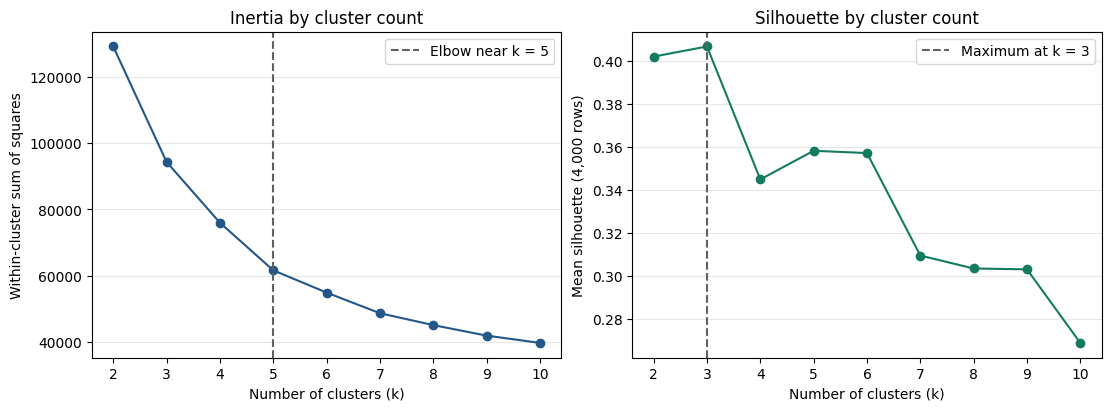

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt

k_results = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    k_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(
            Xs, model.labels_, sample_size=4000, random_state=SEED
        ),
    })

k_comparison = pd.DataFrame(k_results).set_index("k")
best_silhouette_k = int(k_comparison["Silhouette"].idxmax())
print(k_comparison.to_string(formatters={
    "Inertia": "{:,.2f}".format,
    "Silhouette": "{:.6f}".format,
}))
print(f"Highest silhouette: k = {best_silhouette_k}")

fig, (inertia_ax, silhouette_ax) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
inertia_ax.plot(k_comparison.index, k_comparison["Inertia"], "o-", color="#235789")
inertia_ax.axvline(5, linestyle="--", color="#606060", label="Elbow near k = 5")
inertia_ax.set_title("Inertia by cluster count")
inertia_ax.set_ylabel("Within-cluster sum of squares")

silhouette_ax.plot(k_comparison.index, k_comparison["Silhouette"], "o-", color="#137b60")
silhouette_ax.axvline(
    best_silhouette_k, linestyle="--", color="#606060",
    label=f"Maximum at k = {best_silhouette_k}",
)
silhouette_ax.set_title("Silhouette by cluster count")
silhouette_ax.set_ylabel("Mean silhouette (4,000 rows)")

for ax in (inertia_ax, silhouette_ax):
    ax.set_xlabel("Number of clusters (k)")
    ax.set_xticks(k_comparison.index)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

plt.show()

The highest silhouette is 0.406817 at k = 3. I read the inertia elbow around k = 5: inertia falls by about 14,369 from k = 4 to k = 5, then by 6,724 from k = 5 to k = 6 and by less at each later step.

In [10]:
from itertools import combinations

single_start_runs = [
    KMeans(n_clusters=7, n_init=1, random_state=SEED + i).fit(Xs)
    for i in range(10)
]
pairwise_ari = [
    adjusted_rand_score(first.labels_, second.labels_)
    for first, second in combinations(single_start_runs, 2)
]
single_start_inertias = [run.inertia_ for run in single_start_runs]

print(f"Pairs of runs: {len(pairwise_ari)}")
print(f"Mean pairwise ARI: {np.mean(pairwise_ari):.6f}")
print(f"Minimum pairwise ARI: {min(pairwise_ari):.6f}")
print(f"Minimum inertia: {min(single_start_inertias):,.2f}")
print(f"Maximum inertia: {max(single_start_inertias):,.2f}")

Pairs of runs: 45
Mean pairwise ARI: 0.731287
Minimum pairwise ARI: 0.485477
Minimum inertia: 48,671.46
Maximum inertia: 54,155.90


At k = 7, the 45 pairs of single-start runs had a mean ARI of 0.7313 and a minimum of 0.4855. Inertia ranged from 48,671.46 to 54,155.90. The differences in both the assignments and inertia support keeping n_init = 10 so K-Means can select the lowest-inertia fit across several starts.

**Recommendation: k = 3.** It gives the best silhouette (0.4068), compared with 0.3583 at the elbow near k = 5 and 0.3096 at k = 7. The elbow gives a case for five finer groups, but I would choose three for their stronger separation. The variation across starts at k = 7 also makes that solution less convincing as a default. Parts 4 to 6 use k = 7 as specified in the assignment.